<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Detailed uRNA exploration of the CosMx melanoma ROI (keratin genes).
> - **Manuscript panels:** Fig. 3E (KRT10 spatial map)
> - **Inputs:** `rois/cosmx_melanoma/data_with_source_score*.zarr`
> - **Outputs:** `*_cosmx_melanoma_scatter_transcript.pdf`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# ROI_processing — CosMx melanoma

Rescued from `4_detailed_analysis/old/detailed_analysis_melanoma.ipynb` (deprecated) and updated to the current pipeline: local `troutpy` dev import, current lustre data paths, and the lambda=0.5 cell-type-annotated zarr. Original exploratory analysis (multivariate, target-score, communication, factor analysis, module analysis) is preserved below the new gene-focused section.

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from pathlib import Path

import hotspot

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


ModuleNotFoundError: No module named 'hotspot'

In [3]:
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [4]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_melanoma")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/cosmx_melanoma")
saving_path.mkdir(parents=True, exist_ok=True)

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_with_source_score_general_annotated_source_score_lambda0.5.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


# 1. Gene expression spatial maps — KRT8 and related markers

KRT8 alongside the other keratin/EMT markers originally highlighted for this dataset (KRT10, KRT1, KRT14, SNAI2, FABP5).

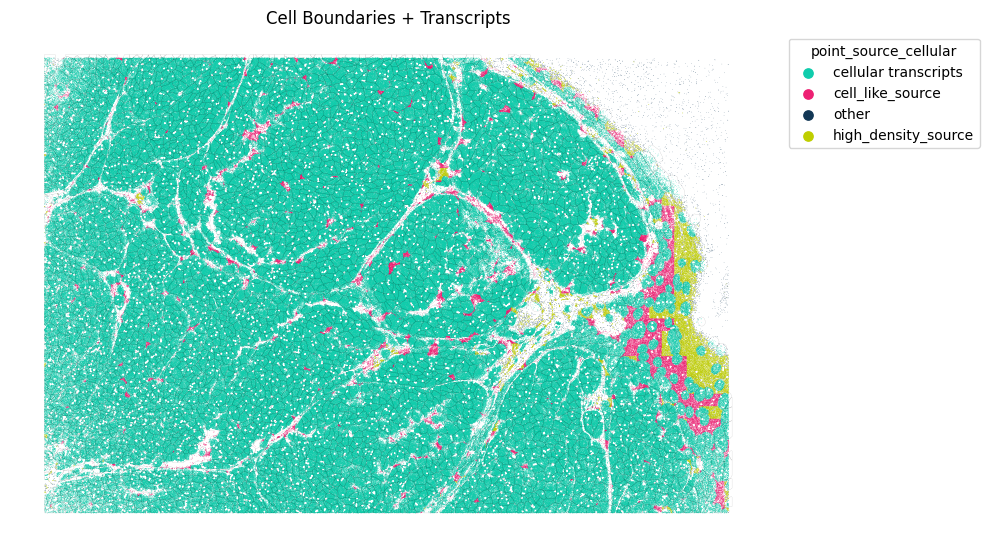

In [5]:
# Genes of interest: KRT8 plus the other keratin/EMT markers originally highlighted for this dataset
genes_of_interest = ['KRT8', 'KRT10', 'KRT1', 'KRT14', 'SNAI2', 'FABP5']

fig, ax = pl.spatial_transcripts(sdata, shapes_key='shapes', scatter_size=0.07, figsize=(10, 10), boundary_linewidth=0.1)
fig.savefig(saving_path / "cosmx_melanoma_all_transcripts.pdf", dpi=300)

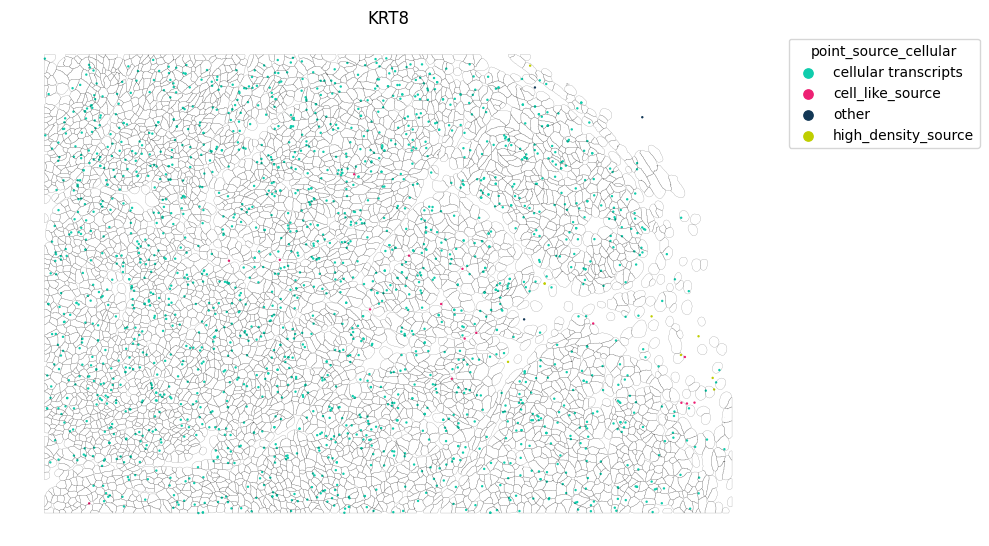

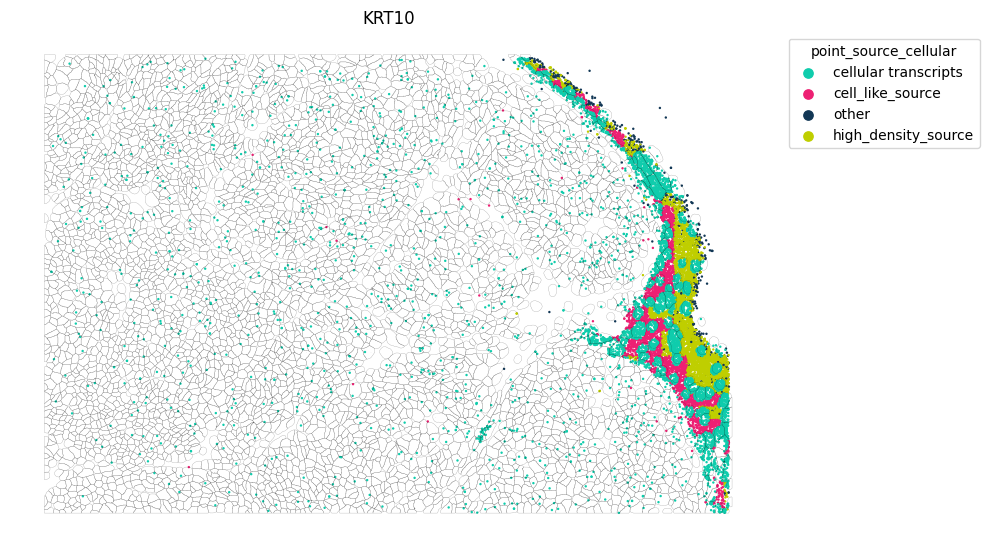

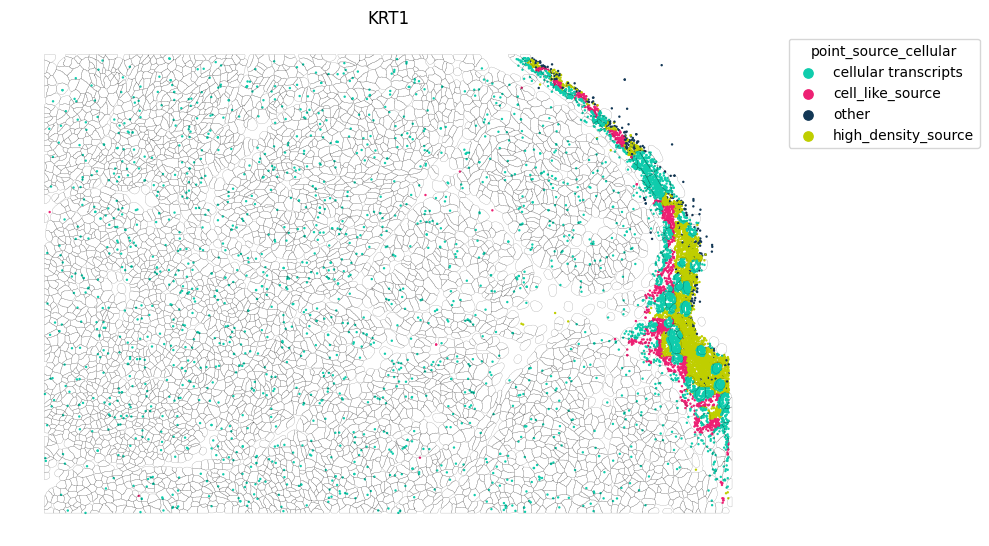

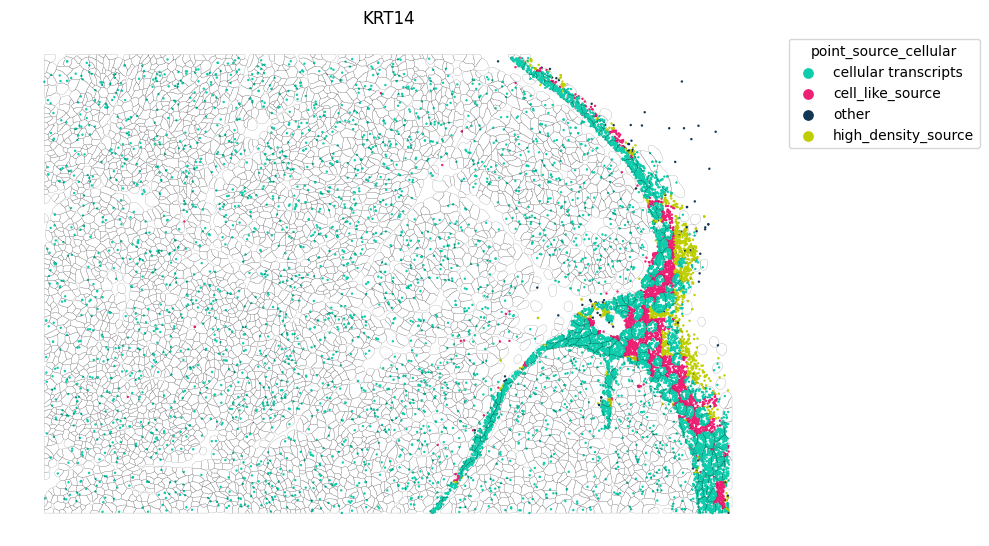

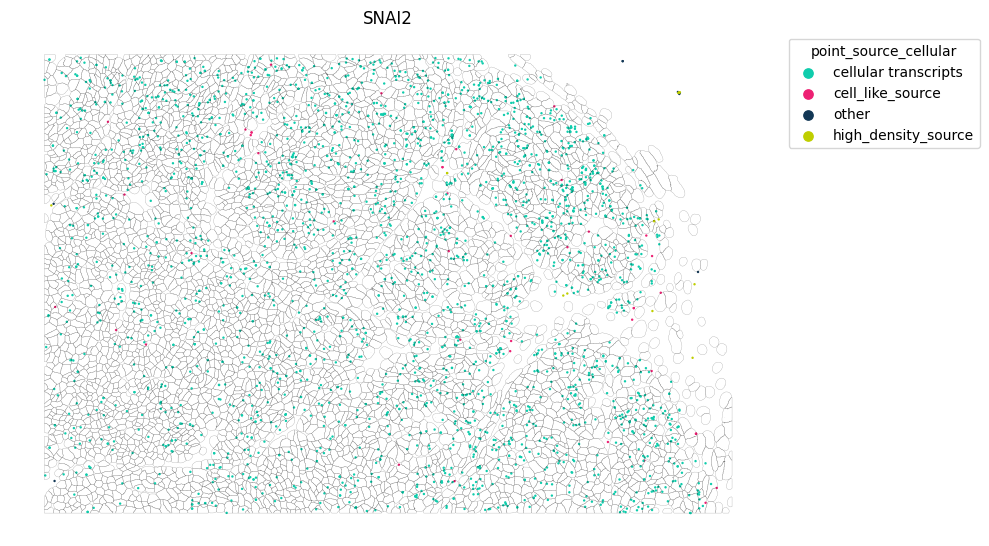

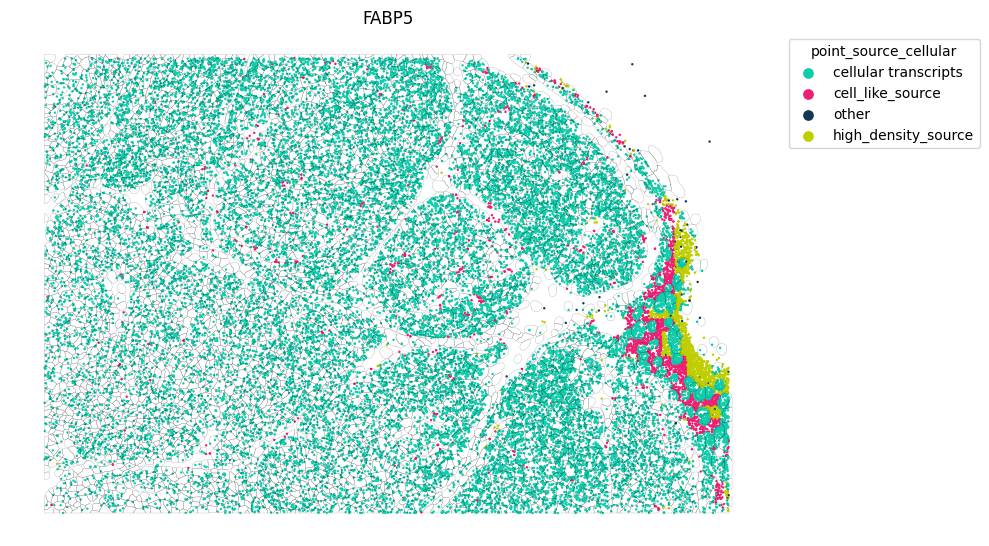

In [6]:
for gene in genes_of_interest:
    fig, ax = pl.spatial_transcripts(
        sdata,
        gene_list=[gene],
        shapes_key='shapes',
        scatter_size=2,
        boundary_linewidth=0.2,
        figsize=(10, 10),
        title=gene,
    )
    fig.savefig(saving_path / f"{gene}_cosmx_melanoma_scatter_transcript.pdf", dpi=300)

# 2. Additional unimodal plots (rescued from deprecated notebook)

In [7]:
fig=troutpy.pl.global_distribution_from_source(sdata)
#plt.savefig(os.path.join(saving_path,"cosmx_melanma_distribution.pdf"), dpi=300)

ValueError: Clustering key 'kmeans_from_distribution' not found in sdata['xrna_metadata'].var

In [8]:
troutpy.pl.diffusion_results(sdata,label_top_n_x=20,label_top_n_y=10)

TypeError: diffusion_results() got an unexpected keyword argument 'label_top_n_x'

In [9]:
troutpy.pl.metric_scatter(sdata,x='mean_displacement',y='logfoldratio_over_noise',label_top_n_x=10)

KeyError: 'logfoldratio_over_noise'

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


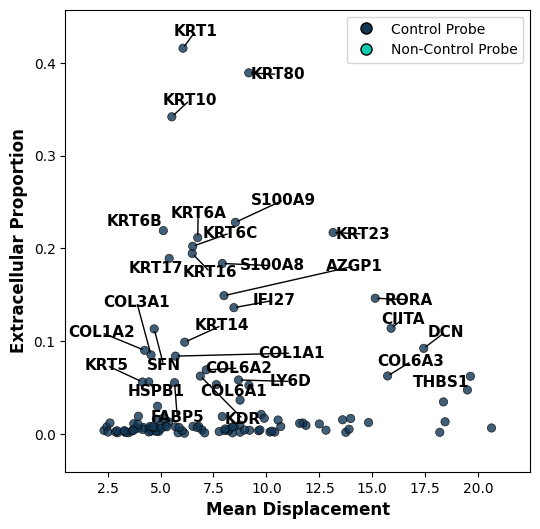

In [10]:
troutpy.pl.metric_scatter(sdata,x='mean_displacement',y='extracellular_proportion',label_top_n_y=30)

In [11]:
troutpy.pl.spatial_inout_expression(sdata,gene='HOXB7',)

ValueError: Gene 'HOXB7' not found in both intracellular and extracellular data.

In [12]:
fig=troutpy.pl.gene_distribution_from_source(sdata,['KRT10','SNAI2'])
plt.savefig(saving_path / "cosmx_melanoma_distribution.pdf", dpi=300)

KeyError: 'distance'

In [13]:
sdata

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_melanoma/data_with_source_score_general_annotated_source_score_lambda0.5.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (3, 576, 696), (3, 288, 348), (3, 144, 174)
├── Labels
│     └── 'labels': DataTree[yx] (576, 696), (288, 348), (144, 174)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 21) (2D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 26) (2D points)
├── Shapes
│     ├── 'grid_squares': GeoDataFrame shape: (2904, 1) (2D shapes)
│     └── 'shapes': GeoDataFrame shape: (4754, 2) (2D shapes)
└── Tables
      ├── 'image_intensity_per_transcript': AnnData (3043815, 3)
      ├── 'segmentation_free_table': AnnData (443, 987)
      ├── 'source_score': AnnData (128238, 4)
      ├── 'structure_table': AnnData (741, 987)
      ├── 'table': AnnData (4738, 987)
      └── 'xrna_metadata': AnnData (0, 

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

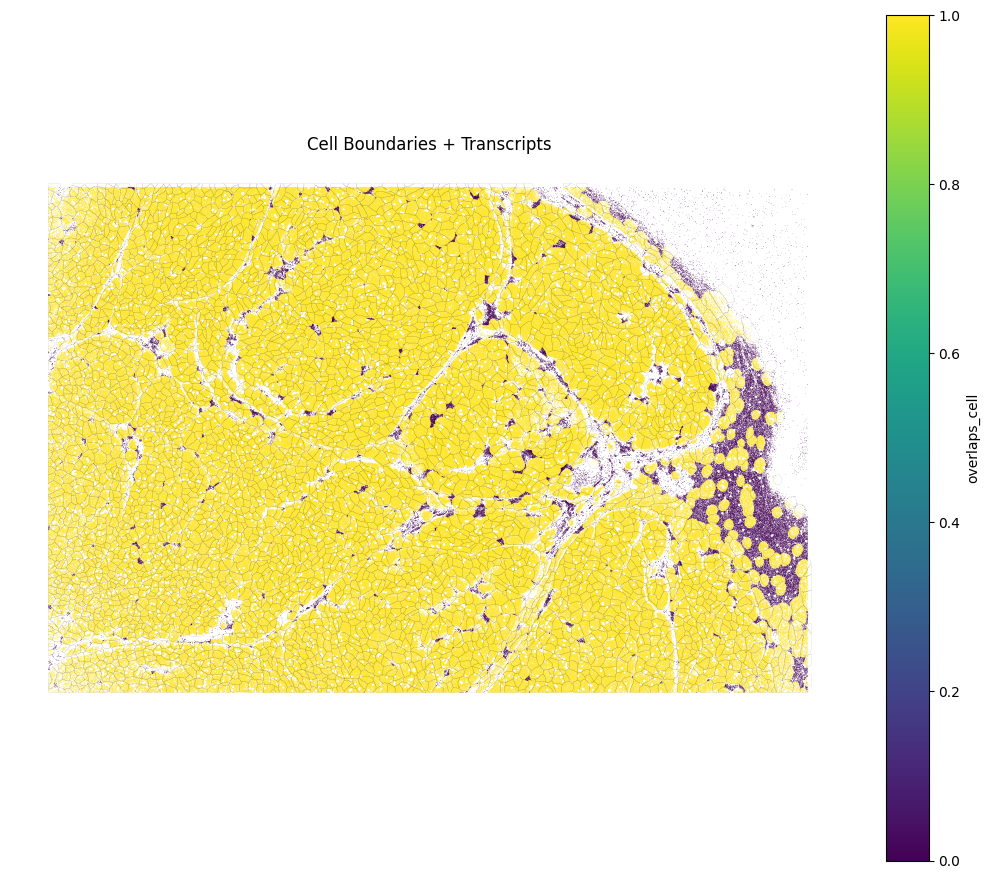

In [14]:
pl.spatial_transcripts(sdata, color_key="overlaps_cell", colormap="viridis", shapes_key='shapes', scatter_size=0.07, figsize=(10,10), boundary_linewidth=0.1)

(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

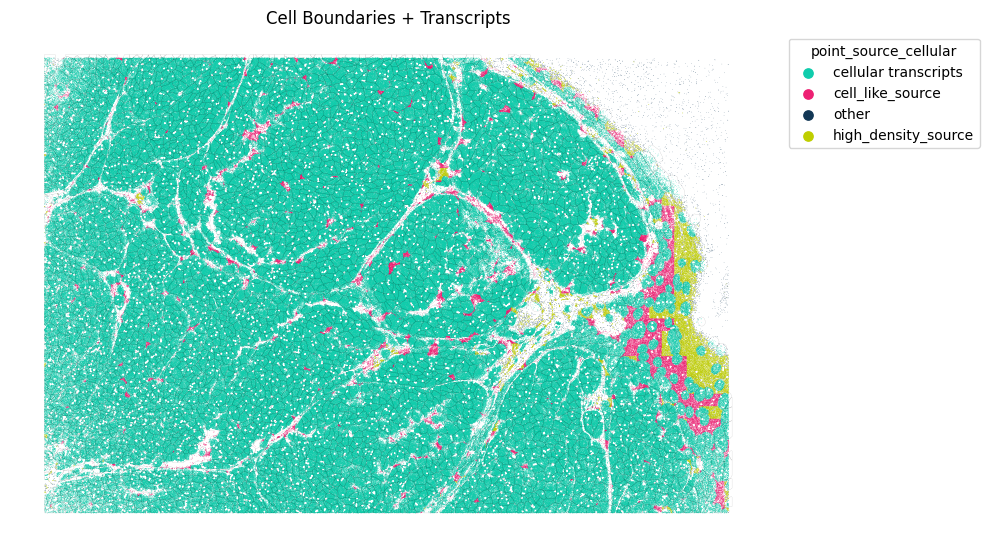

In [15]:
pl.spatial_transcripts(sdata, shapes_key='shapes', scatter_size=0.07, figsize=(10,10), boundary_linewidth=0.1)

In [16]:
troutpy.pl.metric_scatter(
    sdata,
    x="logfoldratio_over_noise",
    y="extracellular_proportion",
    label_top_n_y=10,
    label_bottom_n_y=0,
    label_top_n_x=5
)

KeyError: 'logfoldratio_over_noise'

In [17]:
troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True,x_col='extracellular_proportion',label_top_n_x=5)

TypeError: diffusion_results() got an unexpected keyword argument 'label_top_n_x'

In [18]:
sdata['transcripts']

,gene,cell_id,x,y,z_raw,CellComp,fov,local_x,local_y,transcript_id,overlaps_cell,overlaps_nuclei,control_probe,enrichment_class,density_similarity_score,enrichment_over_random,local_count_in_radius,closest_cell_type,cosine_similarity,prob_is_urna,extracellular,cosine_sim_stainings,prob_is_urna_stainings,extracellular_stainings,point_source,structure_id
npartitions=1,,,,,,,,,,,,,,,,,,,,,,,,,,
,category[unknown],string,float64,float64,int64,string,int64,float64,float64,int64,bool,bool[pyarrow],bool,string,float64,float64,float64,string,float32,float64,bool,float64,float64,bool,string,int64
,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


# 3. Multivariate analysis

In [19]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
# neighbors
sc.pp.neighbors(adata, n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=0.7)
sc.tl.rank_genes_groups(adata, "leiden", method="t-test", n_genes=10)

It seems you use rank_genes_groups on the raw count data. Please logarithmize your data before calling rank_genes_groups.


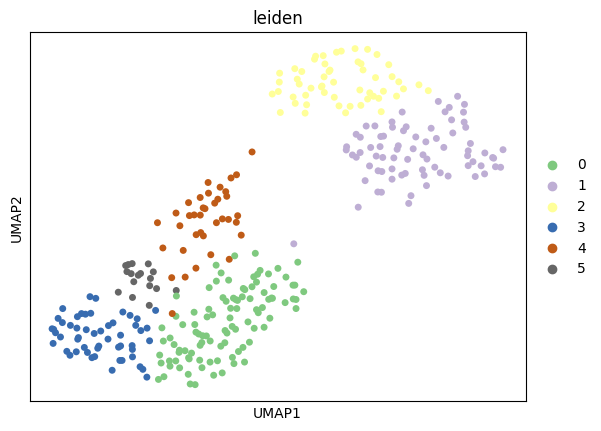

dendrogram data not found (using key=dendrogram_leiden). Running `sc.tl.dendrogram` with default parameters. For fine tuning it is recommended to run `sc.tl.dendrogram` independently.


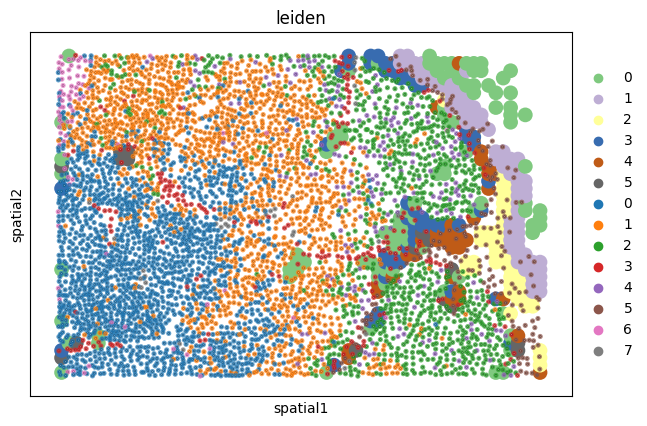

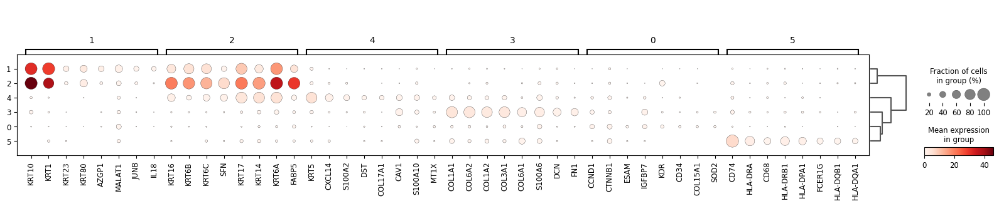

In [20]:
sc.pl.umap(adata, color="leiden", palette="Accent", s=100)
# plot 
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=20, show=False, ax=ax, marker="s")
# fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata["table"],color="leiden",spot_size=7,show=False, ax=ax,add_outline=True,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=8)

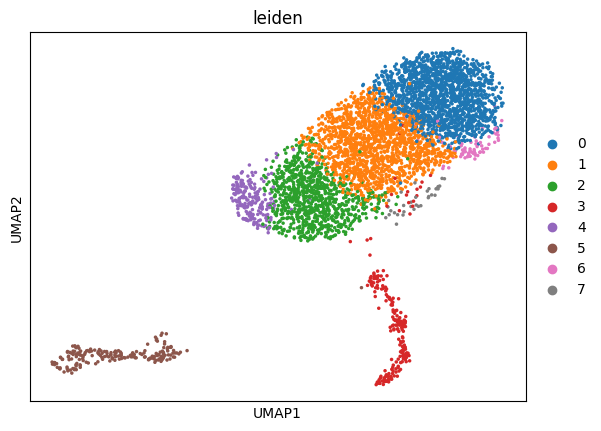

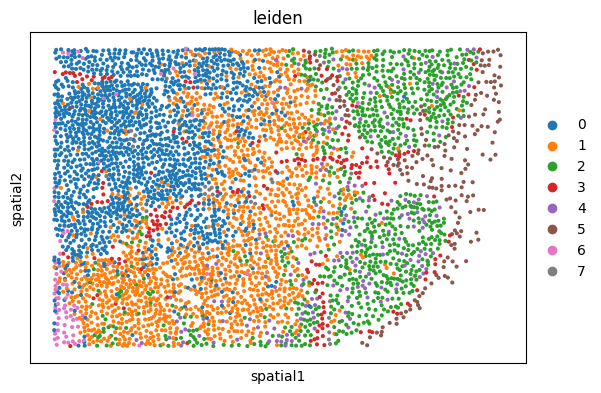

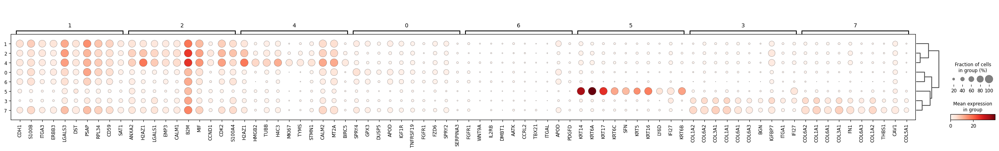

In [21]:
sc.pl.umap(sdata["table"],color="leiden")
sc.pl.spatial(sdata["table"],color="leiden",spot_size=6,add_outline=False,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=10)

In [22]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

AttributeError: module 'troutpy.pl' has no attribute 'spatial_transcripts'

In [23]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',color_key='closest_cell_type',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)

AttributeError: module 'troutpy.pl' has no attribute 'spatial_transcripts'

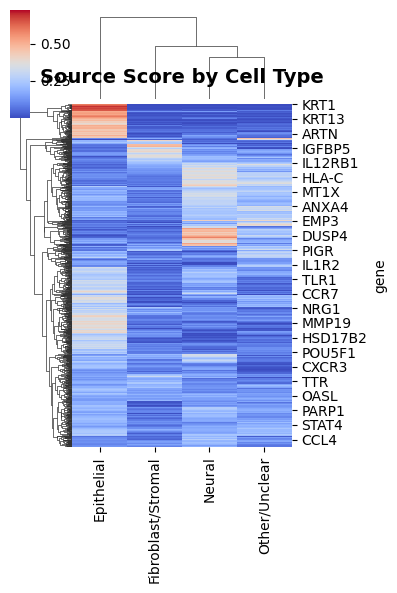

In [24]:
troutpy.pl.source_score_by_celltype(sdata, figsize=(4, 6))

In [25]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

KeyError: 'distance'

In [26]:
troutpy.pl.global_distribution_from_source(sdata, cluster_key="kmeans_distribution", distance_key="distance", n_bins=40, how="collapsed")


ValueError: Clustering key 'kmeans_distribution' not found in sdata['xrna_metadata'].var

In [27]:
troutpy.pl.distributions_by_cluster(sdata, groups=[1])

KeyError: 'kmeans_distribution'

In [28]:
troutpy.pl.gene_distribution_from_source(sdata, ['KRT1'])

KeyError: 'distance'

## Target-score

In [29]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.5,copy=False,celltype_key="leiden",gene_key='gene')

  0%|          | 0/49614 [00:00<?, ?it/s]

  0%|          | 134/49614 [00:00<00:37, 1332.65it/s]

  1%|          | 271/49614 [00:00<00:36, 1350.01it/s]

  1%|          | 408/49614 [00:00<00:36, 1356.58it/s]

  1%|          | 545/49614 [00:00<00:36, 1361.56it/s]

...

 99%|█████████▉| 49198/49614 [00:36<00:00, 1244.92it/s]

 99%|█████████▉| 49324/49614 [00:36<00:00, 1247.76it/s]

100%|█████████▉| 49451/49614 [00:36<00:00, 1253.45it/s]

100%|█████████▉| 49577/49614 [00:36<00:00, 1252.91it/s]

100%|██████████| 49614/49614 [00:36<00:00, 1350.96it/s]

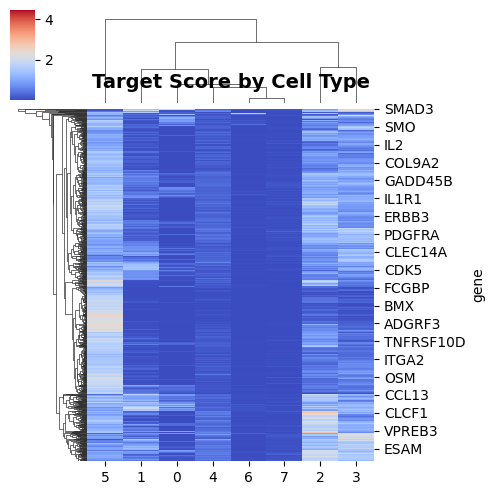

In [30]:
troutpy.pl.target_score_by_celltype(sdata, figsize=(5, 5),gene_key='gene')

## Communication strenght

In [32]:
troutpy.tl.gene_specific_interactions(sdata, copy=False)

UnboundLocalError: local variable 'source_table' referenced before assignment

## Latent factor analysis

In [34]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

{'Factor 1': ['FABP5'], 'Factor 2': ['TYK2'], 'Factor 3': ['COL1A1'], 'Factor 4': ['KRT10'], 'Factor 5': ['KRT5'], 'Factor 6': ['KRT17'], 'Factor 7': ['CD74'], 'Factor 8': ['B2M'], 'Factor 9': ['KRT14'], 'Factor 10': ['MALAT1']}


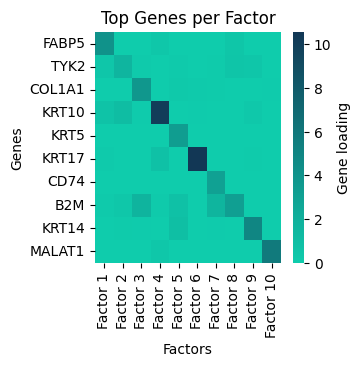

In [36]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=1, cmap="troutpy_reversed")

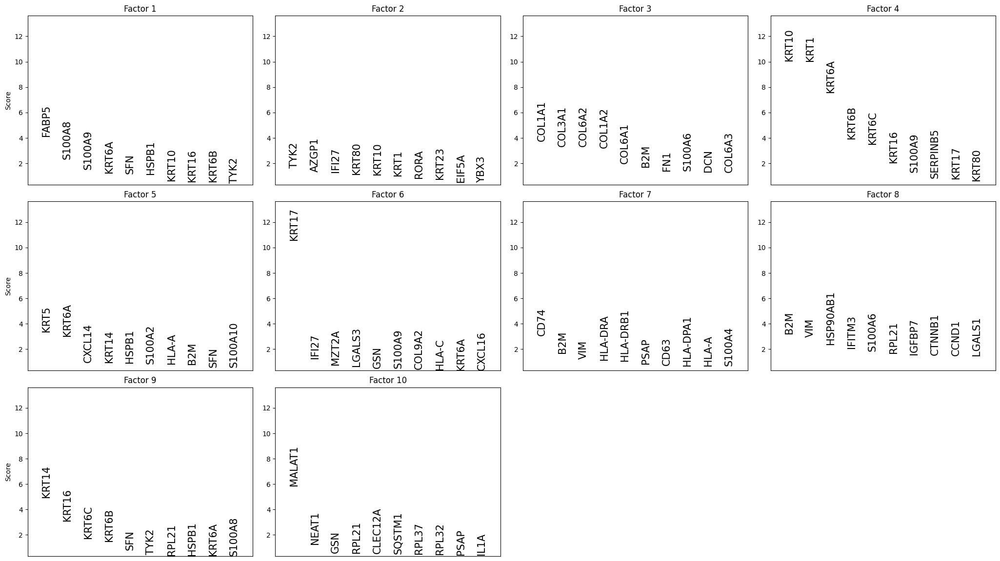

In [37]:
troutpy.pl.rank_factor_genes_loadings(sdata, layer="segmentation_free_table", n_genes=10)

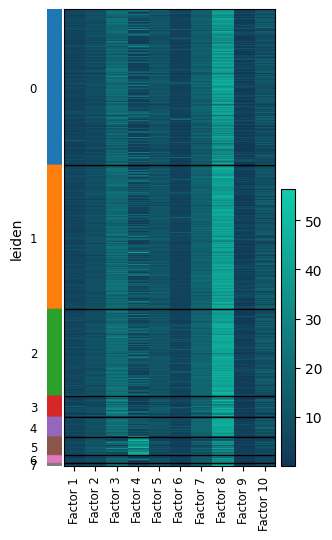

In [38]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap="troutpy", method="heatmap",celltype_key='leiden')

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import troutpy as tp


def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, marker="*", colorbar_loc=None
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.5,
            colorbar_loc=None,
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

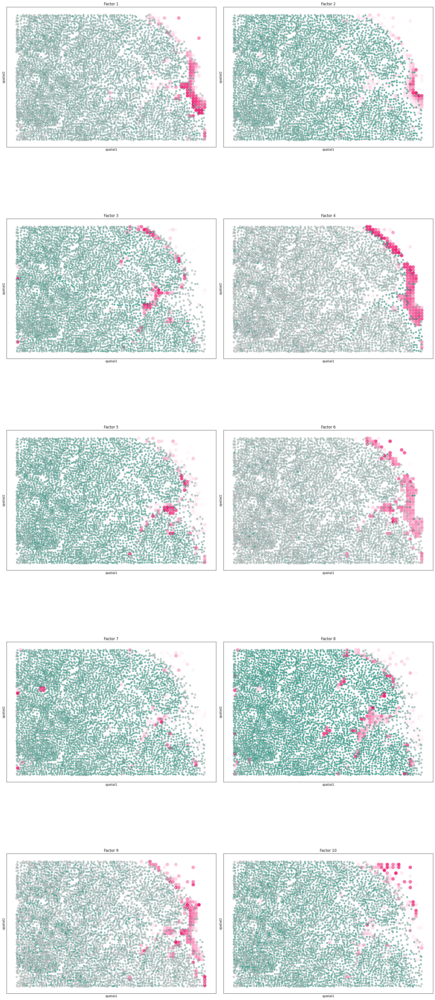

In [40]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=5)

In [41]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT14'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT14')

AttributeError: module 'troutpy.pl' has no attribute 'spatial_transcripts'

In [42]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

AttributeError: module 'troutpy.pl' has no attribute 'spatial_transcripts'

## Multimodal analysis

In [43]:
sdata

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_melanoma/data_with_source_score_general_annotated_source_score_lambda0.5.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (3, 576, 696), (3, 288, 348), (3, 144, 174)
├── Labels
│     └── 'labels': DataTree[yx] (576, 696), (288, 348), (144, 174)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 21) (2D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 26) (2D points)
├── Shapes
│     ├── 'grid_squares': GeoDataFrame shape: (2904, 1) (2D shapes)
│     └── 'shapes': GeoDataFrame shape: (4754, 2) (2D shapes)
└── Tables
      ├── 'image_intensity_per_transcript': AnnData (3043815, 3)
      ├── 'segmentation_free_table': AnnData (338, 981)
      ├── 'source_score': AnnData (128238, 4)
      ├── 'structure_table': AnnData (741, 987)
      ├── 'table': AnnData (4738, 981)
      ├── 'target_score': AnnData (4961

### This is currently not working, to be fixed

In [44]:
image_intensities_per_transcript(
sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=True, copy=False,
)

NameError: name 'image_intensities_per_transcript' is not defined

In [45]:
get_transformation(sdata['morphology_focus'])

Sequence 
    Translation (c, y, x)
        [   0. 1560.  744.]
    Identity 

In [46]:
ad = sdata["image_intensity_per_transcript"]
sc.pl.spatial(ad, color=ad.var.index, spot_size=10, cmap="YlGnBu", vmax="p99", ncols=4)

SyntaxError: positional argument follows keyword argument (816709533.py, line 2)

# Module analysis

In [47]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

NameError: name 'hotspot' is not defined

In [48]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

NameError: name 'hs' is not defined

In [49]:
hs.plot_local_correlations(vmax=10, vmin=-10)

NameError: name 'hs' is not defined

In [50]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

NameError: name 'module_scores' is not defined

In [51]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

NameError: name 'modules' is not defined

In [52]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [53]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

NameError: name 'results' is not defined

In [54]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

NameError: name 'results2' is not defined

In [55]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

ValueError: Gene 'Gap43' not found in both intracellular and extracellular data.

In [56]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

NameError: name 'results' is not defined

In [57]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

NameError: name 'results' is not defined

In [58]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

NameError: name 'modules' is not defined

In [59]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

ValueError: Gene 'CAVIN2' not found in both intracellular and extracellular data.

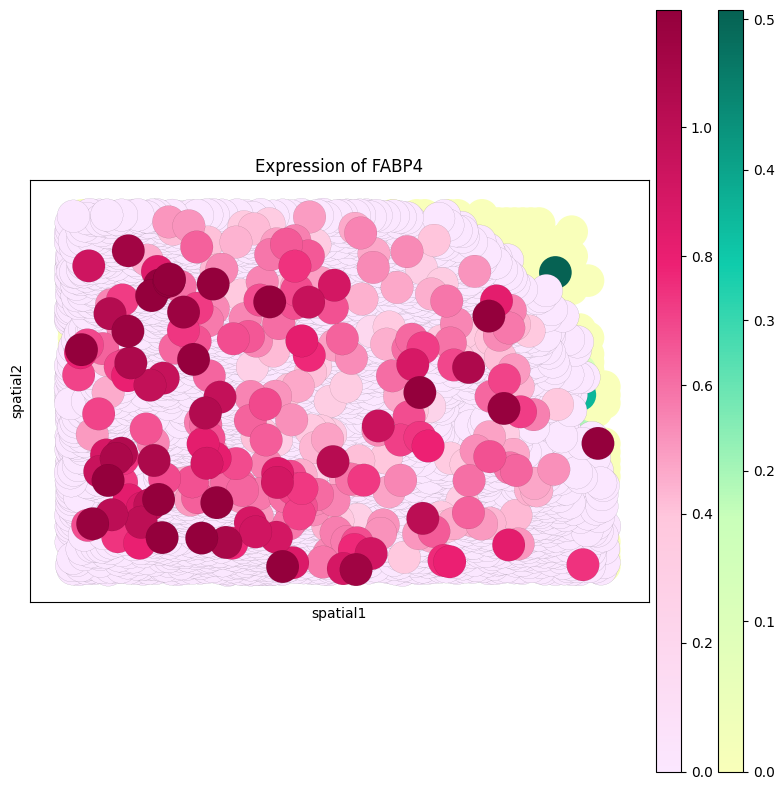

In [60]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [61]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

NameError: name 'merged_info' is not defined

In [62]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

NameError: name 'results' is not defined

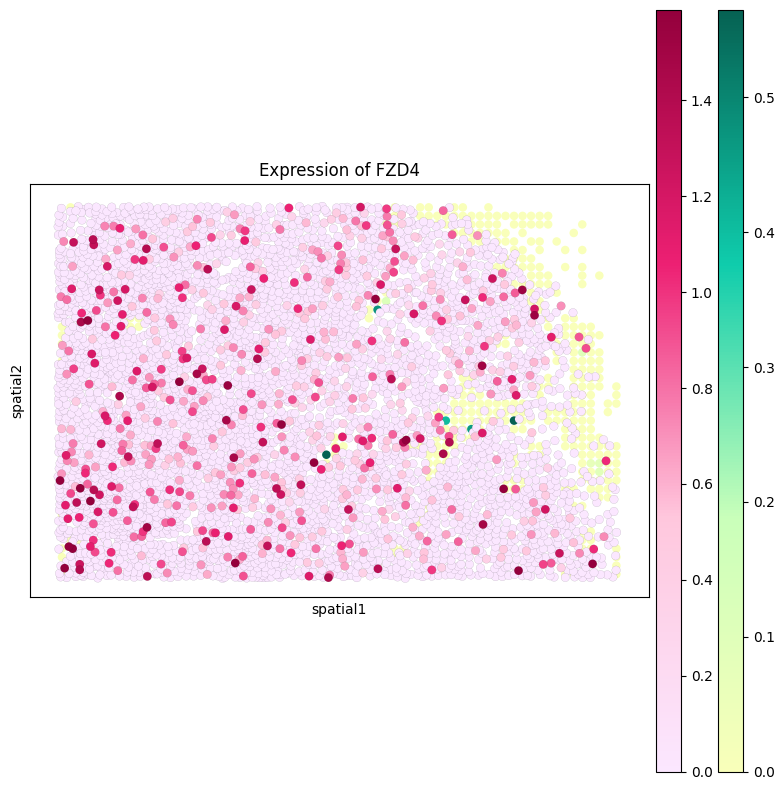

In [63]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [64]:
trans = sdata["transcripts"].compute()

In [65]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [66]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [67]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [68]:
trans2.to_csv(saving_path / "trans2.csv")